# 📘 7.4 Runge-Kutta Methods

### Improving an ODE step by sampling more than one local slope

Explicit Euler uses only the slope at the beginning of each step. When the rate
changes substantially inside that interval, one left-end slope is a poor summary.
**Runge-Kutta (RK) methods** evaluate the ODE at carefully selected intermediate
states and combine those slope estimates into a more accurate update.

This notebook develops:

* the second-order midpoint Runge-Kutta method (RK2);
* the classical fourth-order Runge-Kutta method (RK4); and
* adaptive Runge-Kutta integration using `scipy.integrate.solve_ivp`.

The heated thermal mass from 7.2-7.3 provides a known reference for verification. A
nonlinear falling-body model then connects adaptive integration to irregularly timed
experimental data points.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain why additional within-step slope evaluations can improve accuracy;
* calculate one midpoint RK2 and classical RK4 update;
* identify the coordinate, trial state and units of every RK stage;
* implement reusable fixed-step midpoint and RK4 solvers;
* compare Euler, midpoint and RK4 accuracy per right-hand-side evaluation;
* verify first-, second- and fourth-order global convergence;
* interpret stability functions for a decaying mode;
* explain the difference between fixed and adaptive step size;
* configure `solve_ivp` with tolerances and inspect its diagnostics;
* distinguish adaptive internal solver points from measurement points; and
* evaluate a nonlinear ODE prediction at irregular data coordinates.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* SciPy — [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
* SciPy User Guide — [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp)
* NumPy — [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html)


## 📂 7.4.0 How to use this notebook

Run every code cell in order. No editing or input is required. Pause at the stage
diagrams and predict whether each trial state should increase or decrease the next
slope.

> ### 🧭 Theory preface
> RK notation can look dense because one step contains several named slopes. Each
> stage repeats the same simple operation: construct a trial time and state, then ask
> the ODE for the derivative there. Focus on the physical meaning and units of each
> stage before considering the final weights.
>
> Higher order improves truncation error for a smooth problem, but does not validate
> the ODE model, its parameters or its measured inputs. Stability, discontinuities and
> tolerances still require engineering judgement.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

BLUE = "#006DAE"
ORANGE = "#E57200"
GREEN = "#00843D"
RED = "#C8102E"
PURPLE = "#7A52A1"

C_J_K = 1800.0
H_W_K = 7.5
AMBIENT_C = 22.0
HEATER_W = 150.0
INITIAL_C = 22.0
TAU_S = C_J_K/H_W_K
EQUILIBRIUM_C = AMBIENT_C + HEATER_W/H_W_K

def thermal_rhs(time_s, temperature_c, power_w=HEATER_W,
                capacitance_j_k=C_J_K, conductance_w_k=H_W_K,
                ambient_c=AMBIENT_C):
    '''Return dT/dt [K/s] for the lumped thermal model.'''
    return (
        power_w-conductance_w_k*(temperature_c-ambient_c)
    )/capacitance_j_k

def thermal_exact(time_s, initial_c=INITIAL_C, power_w=HEATER_W,
                  capacitance_j_k=C_J_K, conductance_w_k=H_W_K,
                  ambient_c=AMBIENT_C, initial_time_s=0.0):
    '''Exact constant-input thermal trajectory used for validation.'''
    time_s = np.asarray(time_s, dtype=float)
    equilibrium_c = ambient_c + power_w/conductance_w_k
    tau_s = capacitance_j_k/conductance_w_k
    return equilibrium_c + (initial_c-equilibrium_c)*np.exp(
        -(time_s-initial_time_s)/tau_s
    )

print(f"Thermal time constant = {TAU_S:.1f} s; "
      f"equilibrium = {EQUILIBRIUM_C:.1f} °C")


Thermal time constant = 240.0 s; equilibrium = 42.0 °C


### 📖 Core language for 7.4

| Term | Meaning |
|---|---|
| $k_j$ | Stage-$j$ derivative estimate with the same units as $dy/dt$ |
| **Trial state** | Temporary state used to evaluate a later stage; not yet the accepted next state |
| **Stage** | One right-hand-side evaluation inside a time step |
| **Stage weight** | Coefficient used to combine stage derivatives |
| **Order $p$** | Global error decreases approximately as $h^p$ in the asymptotic regime |
| **Embedded pair** | Two RK formulas of different order sharing stages to estimate local error |
| **Adaptive step** | Internally selected step size changed in response to an error estimate |

The symbol $k_j$ represents a **rate**, not a state increment. Multiplication by the
time step $h$ converts that rate into a predicted state change.


## 📂 7.4.1 Why one slope may be insufficient

Euler predicts

$$
y_{n+1}=y_n+h f(t_n,y_n).
$$

This is exact for a trajectory with constant slope over the step. For the thermal
system, the slope decreases during heating because heat loss grows as temperature
rises. A better method can first predict a representative state inside the step,
evaluate the changed slope there, and use that information in the final update.


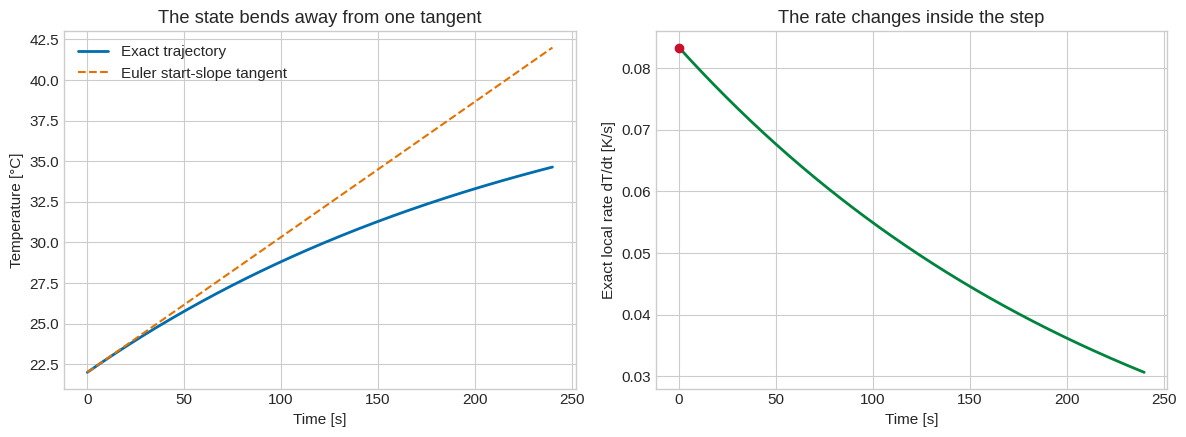

In [ ]:
h_demo = 240.0
t0 = 0.0
T0 = INITIAL_C
k_start = thermal_rhs(t0, T0)

local_time = np.linspace(t0, t0+h_demo, 400)
exact_local = thermal_exact(local_time)
slope_along_exact = thermal_rhs(local_time, exact_local)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(local_time, exact_local, color=BLUE, linewidth=2,
             label="Exact trajectory")
axes[0].plot(local_time, T0+k_start*(local_time-t0), color=ORANGE,
             linestyle="--", label="Euler start-slope tangent")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Temperature [°C]")
axes[0].set_title("The state bends away from one tangent")
axes[0].legend()

axes[1].plot(local_time, slope_along_exact, color=GREEN, linewidth=2)
axes[1].scatter(t0, k_start, color=RED, zorder=4)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Exact local rate dT/dt [K/s]")
axes[1].set_title("The rate changes inside the step")
fig.tight_layout()
plt.show()


## 📂 7.4.2 Midpoint Runge-Kutta method (RK2)

The explicit midpoint method uses two stages:

$$
k_1=f(t_n,y_n),
$$

$$
y_{n+\frac12}^{\mathrm{trial}}=y_n+\frac{h}{2}k_1,
\qquad
k_2=f\!\left(t_n+\frac{h}{2},
y_{n+\frac12}^{\mathrm{trial}}\right),
$$

followed by

$$
\boxed{y_{n+1}=y_n+h k_2}.
$$

$k_1$ predicts a trial state at the midpoint. $k_2$ is the slope evaluated at that
trial midpoint and is used across the full step. The trial state is not automatically
the true midpoint state and is not included as an accepted output coordinate.


## 📂 7.4.3 One midpoint thermal step

For $h=240$ s:

1. evaluate the initial rate $k_1$;
2. advance by $h/2=120$ s using $k_1$ to construct a trial midpoint temperature;
3. evaluate $k_2$ at that trial midpoint; and
4. update the original state using $h k_2$.

Every $k_j$ below has units K/s. Every product $h k_j$ has units K.


k1 = 0.083333 K/s
Trial midpoint temperature = 32.000 °C
k2 = 0.041667 K/s
Euler next state = 42.000 °C
Midpoint RK2 next state = 32.000 °C
Exact next state = 34.642 °C


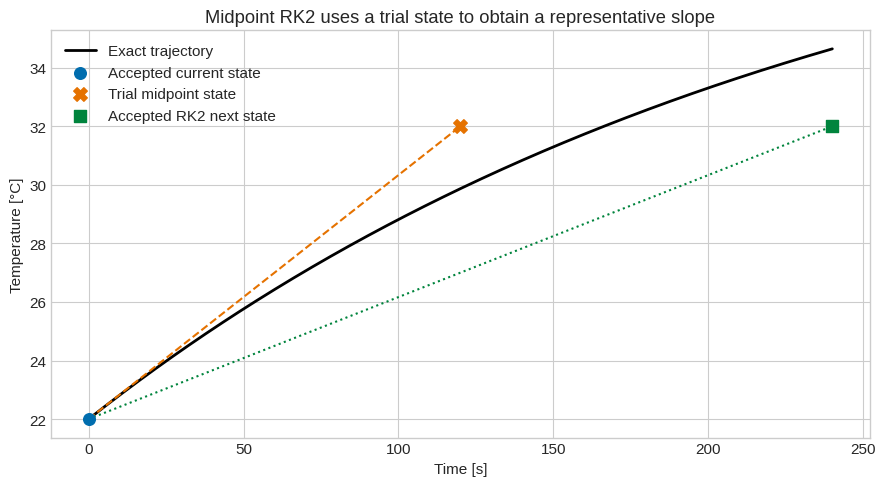

In [ ]:
k1_mid = thermal_rhs(t0, T0)
trial_midpoint = T0 + 0.5*h_demo*k1_mid
k2_mid = thermal_rhs(t0+0.5*h_demo, trial_midpoint)
T_midpoint_next = T0 + h_demo*k2_mid
T_euler_next = T0 + h_demo*k1_mid
T_exact_next = thermal_exact(h_demo)

print(f"k1 = {k1_mid:.6f} K/s")
print(f"Trial midpoint temperature = {trial_midpoint:.3f} °C")
print(f"k2 = {k2_mid:.6f} K/s")
print(f"Euler next state = {T_euler_next:.3f} °C")
print(f"Midpoint RK2 next state = {T_midpoint_next:.3f} °C")
print(f"Exact next state = {T_exact_next:.3f} °C")

plt.figure(figsize=(9, 5))
plt.plot(local_time, exact_local, color="black", linewidth=2,
         label="Exact trajectory")
plt.scatter([t0], [T0], color=BLUE, s=70, label="Accepted current state", zorder=4)
plt.scatter([t0+h_demo/2], [trial_midpoint], marker="X", color=ORANGE,
            s=95, label="Trial midpoint state", zorder=4)
plt.scatter([t0+h_demo], [T_midpoint_next], marker="s", color=GREEN,
            s=70, label="Accepted RK2 next state", zorder=4)
plt.plot([t0, t0+h_demo/2], [T0, trial_midpoint], color=ORANGE,
         linestyle="--")
plt.plot([t0, t0+h_demo], [T0, T_midpoint_next], color=GREEN,
         linestyle=":")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("Midpoint RK2 uses a trial state to obtain a representative slope")
plt.legend()
plt.tight_layout()
plt.show()


The midpoint update is much closer to the exact state than Euler for this step. It
achieved this with two right-hand-side evaluations instead of one.


## 📂 7.4.4 Classical fourth-order Runge-Kutta method (RK4)

Classical RK4 uses four stage rates:

$$
\begin{aligned}
k_1 &= f(t_n,y_n),\\
k_2 &= f\!\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_1\right),\\
k_3 &= f\!\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_2\right),\\
k_4 &= f(t_n+h,y_n+h k_3).
\end{aligned}
$$

The accepted update is

$$
\boxed{
y_{n+1}=y_n+
\frac{h}{6}(k_1+2k_2+2k_3+k_4)
}.
$$

The final weighted rate is

$$
\bar{k}=\frac{k_1+2k_2+2k_3+k_4}{6}.
$$

The weights are chosen so Taylor-series terms match through fourth order. They are
not empirical parameters trained from the trajectory data.


### Why are there two midpoint stages?

$k_2$ uses a midpoint state predicted from the initial slope. $k_3$ constructs a new
midpoint trial using $k_2$. These are two different candidate states at the same time
coordinate. Neither is an accepted half-step output; both exist to improve the final
full-step slope combination.


 stage   trial time [s]   trial T [°C]   rate k [K/s]
   1              0.0        22.0000        0.083333
   2            120.0        32.0000        0.041667
   3            120.0        27.0000        0.062500
   4            240.0        37.0000        0.020833

Weighted rate = 0.052083 K/s
RK4 next state = 34.50000 °C
Exact next state = 34.64241 °C


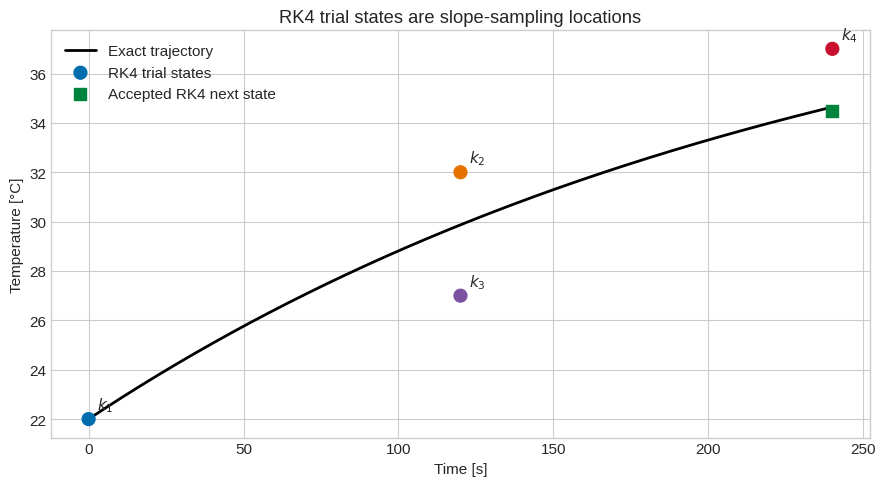

In [ ]:
k1 = thermal_rhs(t0, T0)
T_trial_2 = T0 + 0.5*h_demo*k1
k2 = thermal_rhs(t0+0.5*h_demo, T_trial_2)
T_trial_3 = T0 + 0.5*h_demo*k2
k3 = thermal_rhs(t0+0.5*h_demo, T_trial_3)
T_trial_4 = T0 + h_demo*k3
k4 = thermal_rhs(t0+h_demo, T_trial_4)
weighted_rate = (k1+2*k2+2*k3+k4)/6
T_rk4_next = T0+h_demo*weighted_rate

print(" stage   trial time [s]   trial T [°C]   rate k [K/s]")
stage_rows = [
    (1, t0, T0, k1),
    (2, t0+h_demo/2, T_trial_2, k2),
    (3, t0+h_demo/2, T_trial_3, k3),
    (4, t0+h_demo, T_trial_4, k4),
]
for stage, trial_time, trial_temperature, rate in stage_rows:
    print(f" {stage:3d}   {trial_time:14.1f}   {trial_temperature:12.4f}   {rate:13.6f}")
print(f"\nWeighted rate = {weighted_rate:.6f} K/s")
print(f"RK4 next state = {T_rk4_next:.5f} °C")
print(f"Exact next state = {T_exact_next:.5f} °C")

plt.figure(figsize=(9, 5))
plt.plot(local_time, exact_local, color="black", linewidth=2,
         label="Exact trajectory")
stage_times = [row[1] for row in stage_rows]
stage_temperatures = [row[2] for row in stage_rows]
plt.scatter(stage_times, stage_temperatures, c=[BLUE, ORANGE, PURPLE, RED],
            s=85, zorder=4, label="RK4 trial states")
for stage, trial_time, trial_temperature, _ in stage_rows:
    plt.annotate(f"$k_{stage}$", (trial_time, trial_temperature),
                 xytext=(6, 7), textcoords="offset points")
plt.scatter(h_demo, T_rk4_next, marker="s", color=GREEN, s=80,
            label="Accepted RK4 next state", zorder=5)
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("RK4 trial states are slope-sampling locations")
plt.legend()
plt.tight_layout()
plt.show()


### 🧠 Interpretation

The trial states do not need to lie exactly on the true trajectory. Their stage rates
are combined so the final update has high-order accuracy for smooth problems. Saving
every trial state as if it were an accepted physical prediction would misrepresent the
algorithm.


## 📂 7.4.5 Reusable fixed-step implementations

The model function and numerical update remain separate. Each step function below
returns one accepted next state and reports its number of right-hand-side evaluations.
A shared driver handles the time interval and shortened final step.


In [ ]:
def euler_step(rhs, time, state, step):
    return state+step*rhs(time, state), 1

def midpoint_step(rhs, time, state, step):
    k1 = rhs(time, state)
    k2 = rhs(time+step/2, state+step*k1/2)
    return state+step*k2, 2

def rk4_step(rhs, time, state, step):
    k1 = rhs(time, state)
    k2 = rhs(time+step/2, state+step*k1/2)
    k3 = rhs(time+step/2, state+step*k2/2)
    k4 = rhs(time+step, state+step*k3)
    return state+step*(k1+2*k2+2*k3+k4)/6, 4

def fixed_step_scalar(rhs, time_span, initial_state, step_size, step_function):
    '''Integrate one scalar IVP with a supplied explicit step function.'''
    start_time, final_time = map(float, time_span)
    if final_time <= start_time or step_size <= 0:
        raise ValueError("Require final_time > start_time and step_size > 0")
    times = [start_time]
    states = [float(initial_state)]
    evaluations = 0
    while times[-1] < final_time:
        h_n = min(step_size, final_time-times[-1])
        next_state, calls = step_function(
            rhs, times[-1], states[-1], h_n
        )
        times.append(times[-1]+h_n)
        states.append(next_state)
        evaluations += calls
    return np.asarray(times), np.asarray(states), evaluations

for name, method in [
    ("Euler", euler_step), ("Midpoint RK2", midpoint_step), ("Classical RK4", rk4_step)
]:
    t_num, T_num, nfev = fixed_step_scalar(
        thermal_rhs, (0.0, 900.0), INITIAL_C, 120.0, method
    )
    error = np.max(np.abs(T_num-thermal_exact(t_num)))
    print(f"{name:14s}: {nfev:3d} RHS evaluations, max error {error:.6f} °C")


Euler         :   8 RHS evaluations, max error 2.357589 °C
Midpoint RK2  :  16 RHS evaluations, max error 0.454911 °C
Classical RK4 :  32 RHS evaluations, max error 0.005828 °C


## 📂 7.4.6 Accuracy versus right-hand-side cost

One fixed step costs one ODE evaluation for Euler, two for midpoint RK2 and four for
RK4. If the right-hand side contains an expensive simulation or property calculation,
function evaluations can dominate runtime. A higher-stage method is valuable when its
error reduction outweighs the additional cost.


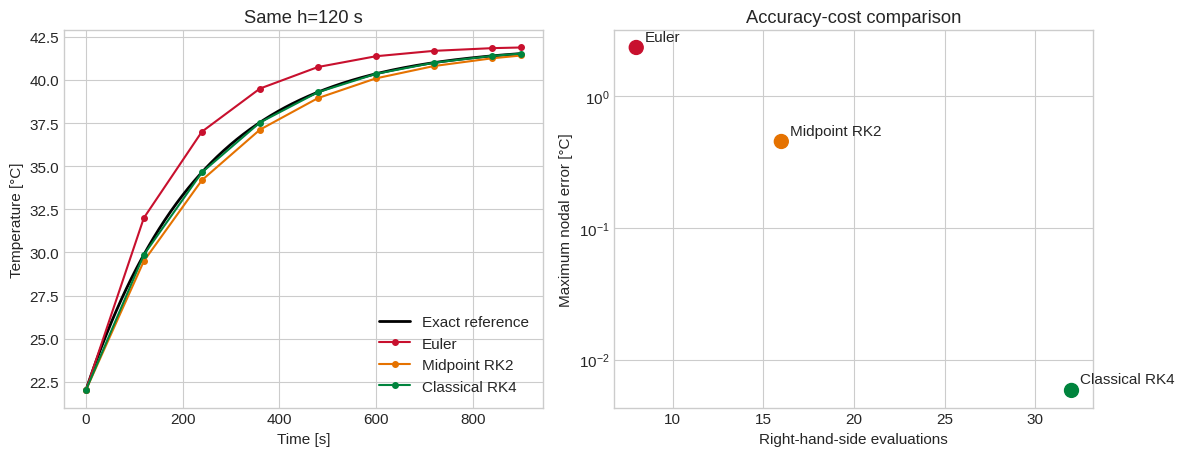

In [ ]:
comparison_step = 120.0
methods = [
    ("Euler", euler_step, RED),
    ("Midpoint RK2", midpoint_step, ORANGE),
    ("Classical RK4", rk4_step, GREEN),
]
dense_time = np.linspace(0.0, 900.0, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(dense_time, thermal_exact(dense_time), color="black",
             linewidth=2, label="Exact reference")
summary = []
for name, method, color in methods:
    t_num, T_num, nfev = fixed_step_scalar(
        thermal_rhs, (0.0, 900.0), INITIAL_C, comparison_step, method
    )
    max_error = np.max(np.abs(T_num-thermal_exact(t_num)))
    summary.append((name, nfev, max_error))
    axes[0].plot(t_num, T_num, "o-", ms=4, color=color, label=name)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Temperature [°C]")
axes[0].set_title("Same h=120 s")
axes[0].legend()

axes[1].scatter([row[1] for row in summary], [row[2] for row in summary],
                c=[RED, ORANGE, GREEN], s=100)
for name, nfev, error in summary:
    axes[1].annotate(name, (nfev, error), xytext=(6, 5),
                     textcoords="offset points")
axes[1].set_yscale("log")
axes[1].set_xlabel("Right-hand-side evaluations")
axes[1].set_ylabel("Maximum nodal error [°C]")
axes[1].set_title("Accuracy-cost comparison")
fig.tight_layout()
plt.show()


The comparison is not a universal ranking. Method performance depends on the problem,
requested accuracy, stability constraints, event handling and implementation. It does
show why counting accepted steps alone is an incomplete cost measure.


## 📂 7.4.7 Local and global orders

For sufficiently smooth solutions in the stable asymptotic regime:

| Method | Stages per fixed step | Local truncation error | Global truncation error |
|---|---:|---:|---:|
| Euler | 1 | $O(h^2)$ | $O(h)$ |
| Midpoint RK2 | 2 | $O(h^3)$ | $O(h^2)$ |
| Classical RK4 | 4 | $O(h^5)$ | $O(h^4)$ |

“RK4 is fourth order” describes global step-size convergence. It does not mean the ODE
is fourth order, that four state variables are required, or that every answer contains
four correct decimal places.


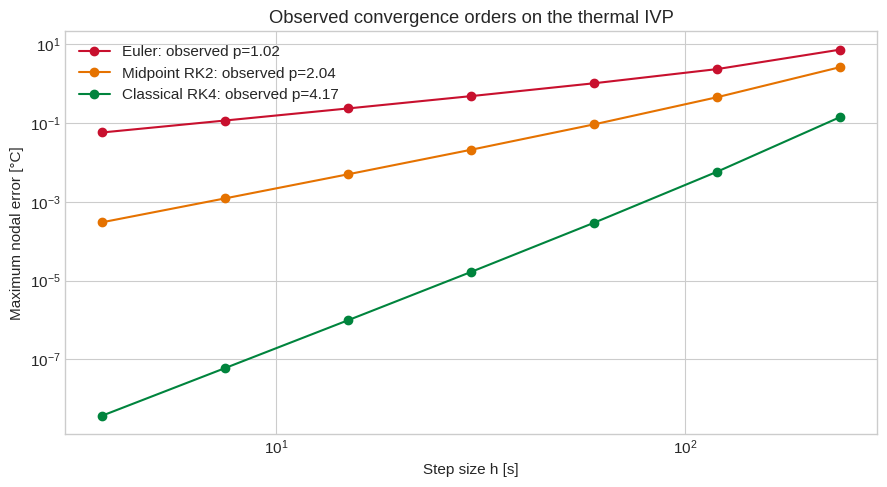

In [ ]:
convergence_steps = 240.0/2**np.arange(0, 7)
convergence_results = {}

for name, method, color in methods:
    errors = []
    for step in convergence_steps:
        t_num, T_num, _ = fixed_step_scalar(
            thermal_rhs, (0.0, 960.0), INITIAL_C, step, method
        )
        errors.append(np.max(np.abs(T_num-thermal_exact(t_num))))
    errors = np.asarray(errors)
    # Use a method-specific range that avoids coarse pre-asymptotic and round-off regions.
    fit_slice = slice(-4, None) if name != "Classical RK4" else slice(1, 5)
    order = np.polyfit(
        np.log(convergence_steps[fit_slice]), np.log(errors[fit_slice]), 1
    )[0]
    convergence_results[name] = (errors, order, color)

plt.figure(figsize=(9, 5))
for name, (errors, order, color) in convergence_results.items():
    plt.loglog(convergence_steps, errors, "o-", color=color,
               label=f"{name}: observed p={order:.2f}")
plt.xlabel("Step size h [s]")
plt.ylabel("Maximum nodal error [°C]")
plt.title("Observed convergence orders on the thermal IVP")
plt.legend()
plt.tight_layout()
plt.show()


### 🧠 Interpretation

The slopes approach the expected orders as $h$ is refined. RK4 eventually approaches
floating-point limits, where further refinement no longer reveals fourth-order
truncation behaviour. Order should be estimated over a visible straight-line region,
not mechanically fitted across every available point.


## 📂 7.4.8 Stability functions for a decaying mode

For $y'=-\lambda y$, define the dimensionless step

$$
r=h\lambda=\frac{h}{\tau}.
$$

A one-step method gives $y_{n+1}=R(-r)y_n$, where $R$ is its stability function:

$$
\begin{aligned}
R_{\mathrm{Euler}}(-r) &= 1-r,\\
R_{\mathrm{RK2}}(-r) &= 1-r+\frac{r^2}{2},\\
R_{\mathrm{RK4}}(-r) &= 1-r+\frac{r^2}{2}-\frac{r^3}{6}+\frac{r^4}{24}.
\end{aligned}
$$

Numerical decay requires $|R(-r)|<1$. Midpoint RK2 has higher accuracy than Euler but
the same stability limit $r<2$ along this negative real axis. Classical RK4 extends
the limit to approximately $r<2.785$.


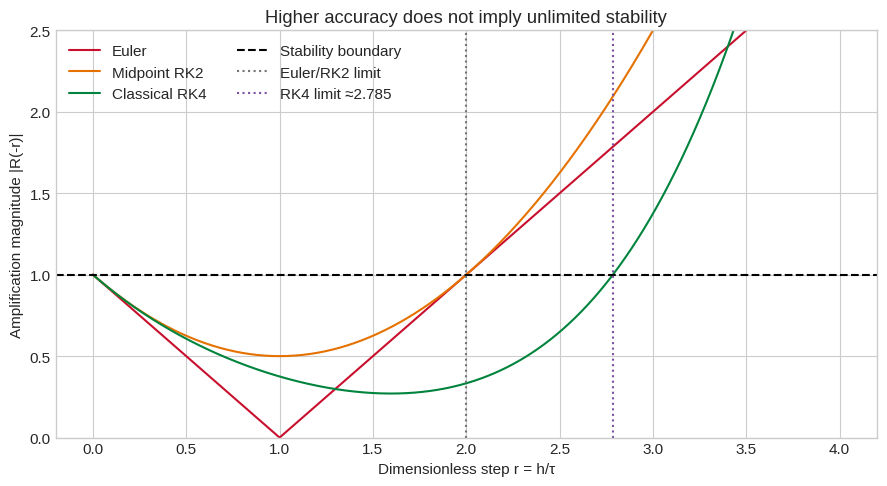

In [ ]:
r = np.linspace(0.0, 4.0, 600)
R_euler = 1-r
R_midpoint = 1-r+r**2/2
R_rk4 = 1-r+r**2/2-r**3/6+r**4/24

plt.figure(figsize=(9, 5))
plt.plot(r, np.abs(R_euler), color=RED, label="Euler")
plt.plot(r, np.abs(R_midpoint), color=ORANGE, label="Midpoint RK2")
plt.plot(r, np.abs(R_rk4), color=GREEN, label="Classical RK4")
plt.axhline(1.0, color="black", linestyle="--", label="Stability boundary")
plt.axvline(2.0, color="0.45", linestyle=":", label="Euler/RK2 limit")
plt.axvline(2.785, color=PURPLE, linestyle=":", label="RK4 limit ≈2.785")
plt.ylim(0, 2.5)
plt.xlabel("Dimensionless step r = h/τ")
plt.ylabel("Amplification magnitude |R(-r)|")
plt.title("Higher accuracy does not imply unlimited stability")
plt.legend(ncols=2)
plt.tight_layout()
plt.show()


For the thermal model, RK4's stability limit is roughly
$2.785\tau\approx668$ s. A step near that limit would still be far too large for an
accurate transient. Stability prevents unbounded numerical growth; it does not set an
acceptable engineering error.


## 📂 7.4.9 From fixed to adaptive step size

A fixed $h$ is inefficient when some parts of a trajectory are easy and others change
rapidly. Adaptive RK solvers use an **embedded pair**: two formulas of different order
share stage evaluations and produce a local error estimate.

Conceptually, an adaptive solver repeats:

1. propose a step size;
2. compute two related RK updates;
3. estimate their scaled difference;
4. accept the step if the estimate is sufficiently small;
5. otherwise reject it and retry with a smaller step; and
6. choose the next step from the observed error.

The user supplies tolerances, not a guarantee of global engineering accuracy.


## 📂 7.4.10 Error scaling with `rtol` and `atol`

SciPy compares estimated local error with a component-wise scale of the form

$$
\mathrm{scale}=\mathrm{atol}+\mathrm{rtol}\,|y|.
$$

* `atol` has the same units as the state and protects accuracy when $|y|$ is small.
* `rtol` is dimensionless and controls error relative to the state magnitude.

For multi-state systems with different units or scales, a separate `atol` may be
supplied for each state. Tolerances control the numerical trajectory, not measurement
noise, parameter uncertainty or model-form error.


## 📂 7.4.11 The `solve_ivp` contract

SciPy solves a first-order system written as

```python
derivative = fun(t, y)
```

A minimal call is

```python
solution = solve_ivp(fun, (t0, tf), y0, method="RK45")
```

Here `y0` is an array, even for one state. `RK45` is an explicit embedded Runge-Kutta
pair: a fifth-order formula advances the state and a fourth-order formula estimates
error. It is not the fixed-step classical RK4 method implemented above.


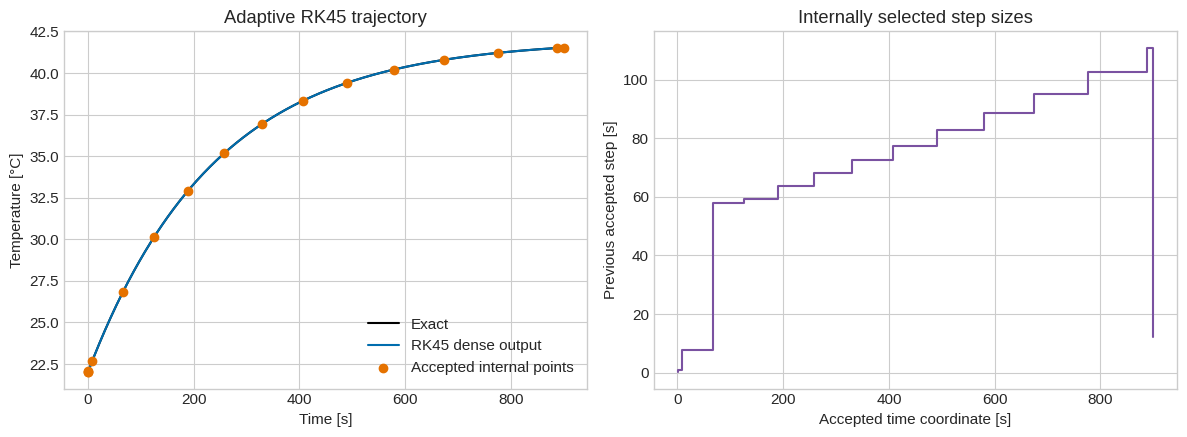

success: True
status: 0
accepted points: 16
right-hand-side evaluations (nfev): 92
maximum displayed error: 7.239e-06 °C


In [ ]:
def thermal_rhs_solver(time_s, state):
    return np.array([thermal_rhs(time_s, state[0])])

adaptive_thermal = solve_ivp(
    thermal_rhs_solver,
    (0.0, 900.0),
    np.array([INITIAL_C]),
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
    dense_output=True,
)

display_time = np.linspace(0.0, 900.0, 500)
display_temperature = adaptive_thermal.sol(display_time)[0]
exact_display = thermal_exact(display_time)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(display_time, exact_display, color="black", label="Exact")
axes[0].plot(display_time, display_temperature, color=BLUE,
             label="RK45 dense output")
axes[0].scatter(adaptive_thermal.t, adaptive_thermal.y[0], color=ORANGE,
                label="Accepted internal points", zorder=4)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Temperature [°C]")
axes[0].set_title("Adaptive RK45 trajectory")
axes[0].legend()

internal_steps = np.diff(adaptive_thermal.t)
axes[1].step(adaptive_thermal.t[1:], internal_steps, where="post", color=PURPLE)
axes[1].set_xlabel("Accepted time coordinate [s]")
axes[1].set_ylabel("Previous accepted step [s]")
axes[1].set_title("Internally selected step sizes")
fig.tight_layout()
plt.show()

print("success:", adaptive_thermal.success)
print("status:", adaptive_thermal.status)
print("accepted points:", adaptive_thermal.t.size)
print("right-hand-side evaluations (nfev):", adaptive_thermal.nfev)
print("maximum displayed error:",
      f"{np.max(np.abs(display_temperature-exact_display)):.3e} °C")


`dense_output=True` creates a continuous interpolant based on the accepted RK steps.
The 500 display coordinates are not 500 internal solver steps. Always inspect
`success`, `message`, `nfev` and the returned coordinate range before using a result.


## 📂 7.4.12 Tighter tolerance usually costs more

The exact thermal solution allows a compact tolerance study. We evaluate every dense
solution on the same comparison grid and plot achieved error against the number of
right-hand-side evaluations.


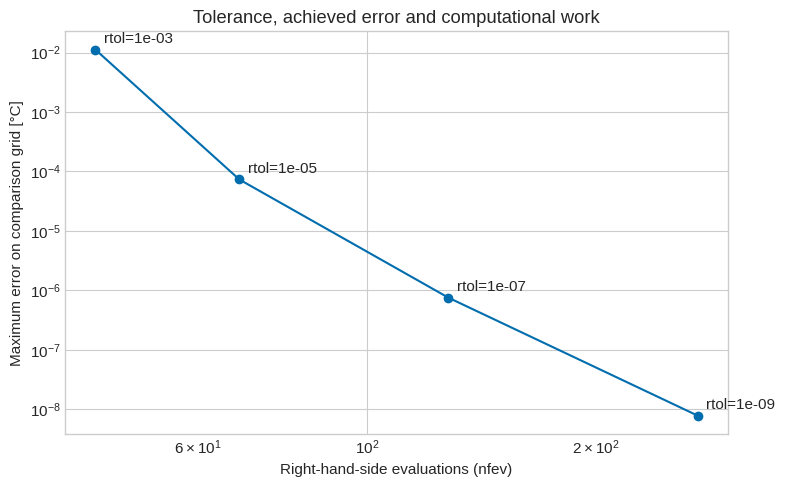

 rtol      atol [°C]   nfev   maximum error [°C]
    1e-03       1e-05     44            1.117e-02
    1e-05       1e-07     68            7.305e-05
    1e-07       1e-09    128            7.492e-07
    1e-09       1e-11    272            7.769e-09


In [ ]:
tolerance_rows = []
for rtol in [1e-3, 1e-5, 1e-7, 1e-9]:
    atol = rtol*0.01  # temperature scale in °C for this demonstration
    solution = solve_ivp(
        thermal_rhs_solver, (0.0, 900.0), [INITIAL_C],
        method="RK45", rtol=rtol, atol=atol, dense_output=True
    )
    prediction = solution.sol(display_time)[0]
    error = np.max(np.abs(prediction-exact_display))
    tolerance_rows.append((rtol, atol, solution.nfev, error))

plt.figure(figsize=(8, 5))
plt.loglog([row[2] for row in tolerance_rows],
           [row[3] for row in tolerance_rows], "o-", color=BLUE)
for rtol, _, nfev, error in tolerance_rows:
    plt.annotate(f"rtol={rtol:.0e}", (nfev, error),
                 xytext=(6, 5), textcoords="offset points")
plt.xlabel("Right-hand-side evaluations (nfev)")
plt.ylabel("Maximum error on comparison grid [°C]")
plt.title("Tolerance, achieved error and computational work")
plt.tight_layout()
plt.show()

print(" rtol      atol [°C]   nfev   maximum error [°C]")
for rtol, atol, nfev, error in tolerance_rows:
    print(f" {rtol:8.0e}  {atol:10.0e}  {nfev:5d}   {error:18.3e}")


Error need not equal the requested tolerance, because the tolerance controls a scaled
local estimate rather than the global error plotted here. Extremely tight tolerances
may waste work when model and measurement uncertainty are much larger.


## 📂 7.4.13 Application: nonlinear falling-body velocity

Take downward velocity $v(t)$ as positive. Gravity acts downward and quadratic drag
opposes motion:

$$
m\frac{dv}{dt}=mg-c_d v|v|,
$$

so

$$
\frac{dv}{dt}=g-\frac{c_d}{m}v|v|.
$$

Here $m$ is mass [kg], $g$ is gravitational acceleration [m/s²], and
$c_d=\rho C_D A/2$ has units kg/m. The $v|v|$ term preserves the direction of drag if
velocity changes sign. This is a nonlinear autonomous first-order ODE.


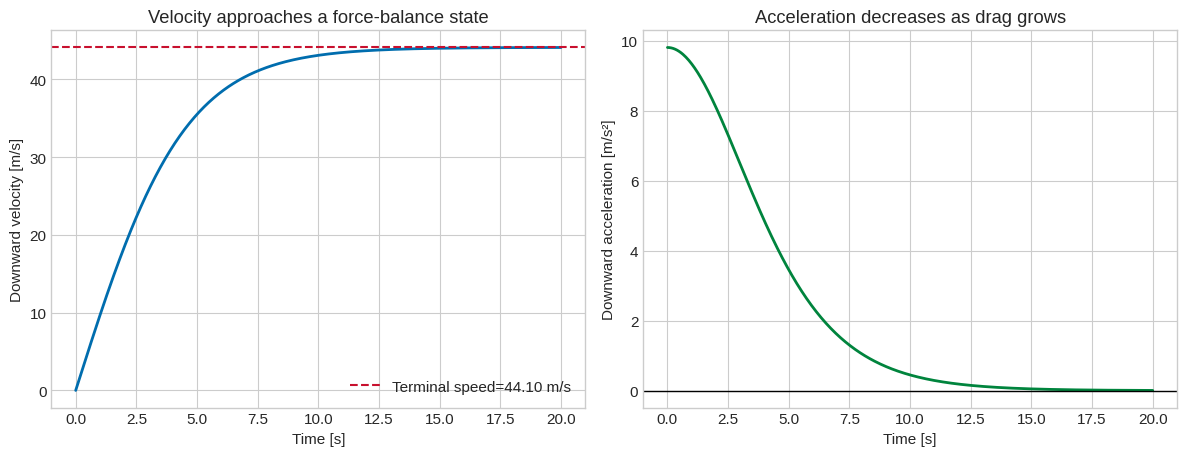

In [ ]:
MASS_BODY_KG = 85.0
GRAVITY_M_S2 = 9.81
AIR_DENSITY_KG_M3 = 1.225
DRAG_COEFFICIENT = 1.0
AREA_M2 = 0.70
DRAG_FACTOR_KG_M = 0.5*AIR_DENSITY_KG_M3*DRAG_COEFFICIENT*AREA_M2

def fall_rhs(time_s, state):
    velocity_m_s = state[0]
    acceleration_m_s2 = (
        GRAVITY_M_S2
        - DRAG_FACTOR_KG_M*velocity_m_s*np.abs(velocity_m_s)/MASS_BODY_KG
    )
    return np.array([acceleration_m_s2])

terminal_velocity = np.sqrt(
    MASS_BODY_KG*GRAVITY_M_S2/DRAG_FACTOR_KG_M
)
fall_solution = solve_ivp(
    fall_rhs, (0.0, 20.0), [0.0], method="RK45",
    rtol=1e-7, atol=1e-9, dense_output=True
)

fall_time = np.linspace(0.0, 20.0, 500)
fall_velocity = fall_solution.sol(fall_time)[0]
fall_acceleration = np.array([
    fall_rhs(t, np.array([v]))[0]
    for t, v in zip(fall_time, fall_velocity)
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(fall_time, fall_velocity, color=BLUE, linewidth=2)
axes[0].axhline(terminal_velocity, color=RED, linestyle="--",
                label=f"Terminal speed={terminal_velocity:.2f} m/s")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Downward velocity [m/s]")
axes[0].set_title("Velocity approaches a force-balance state")
axes[0].legend()

axes[1].plot(fall_time, fall_acceleration, color=GREEN, linewidth=2)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Downward acceleration [m/s²]")
axes[1].set_title("Acceleration decreases as drag grows")
fig.tight_layout()
plt.show()


Terminal velocity is the equilibrium of the velocity ODE: gravity and drag balance so
$dv/dt=0$. The solver approximates the transient approach to that equilibrium; the
equilibrium itself can be checked independently from the force balance.


## 📂 7.4.14 Adaptive points versus irregular measurements

Suppose a camera estimates velocity at irregular times. Those data coordinates are
determined by the experiment. RK45 independently selects internal points to control
numerical error. Dense output evaluates the numerical trajectory at the measurement
times before residuals are calculated.


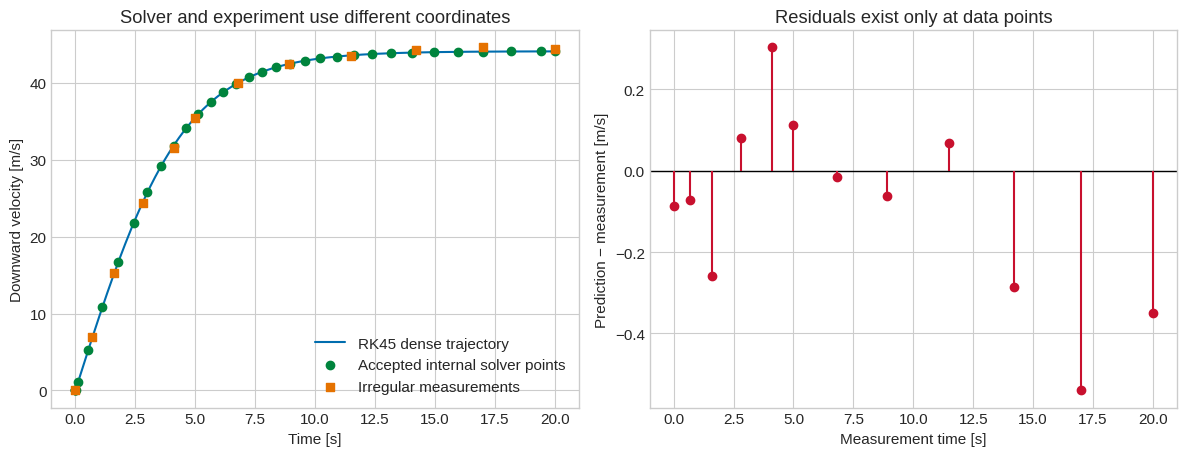

Accepted internal solver points: 34
Experimental data points: 12
Right-hand-side evaluations: 212


In [ ]:
rng = np.random.default_rng(74)
measurement_times = np.array([
    0.0, 0.7, 1.6, 2.8, 4.1, 5.0, 6.8, 8.9, 11.5, 14.2, 17.0, 20.0
])
generating_velocity = fall_solution.sol(measurement_times)[0]
measured_velocity = generating_velocity + rng.normal(
    0.0, 0.35, measurement_times.size
)
predicted_velocity = fall_solution.sol(measurement_times)[0]
residuals = predicted_velocity-measured_velocity

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(fall_time, fall_velocity, color=BLUE,
             label="RK45 dense trajectory")
axes[0].scatter(fall_solution.t, fall_solution.y[0], color=GREEN,
                label="Accepted internal solver points", zorder=4)
axes[0].scatter(measurement_times, measured_velocity, color=ORANGE,
                marker="s", label="Irregular measurements", zorder=5)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Downward velocity [m/s]")
axes[0].set_title("Solver and experiment use different coordinates")
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].stem(measurement_times, residuals, linefmt=RED, markerfmt="o",
             basefmt=" ")
axes[1].set_xlabel("Measurement time [s]")
axes[1].set_ylabel("Prediction − measurement [m/s]")
axes[1].set_title("Residuals exist only at data points")
fig.tight_layout()
plt.show()

print("Accepted internal solver points:", fall_solution.t.size)
print("Experimental data points:", measurement_times.size)
print("Right-hand-side evaluations:", fall_solution.nfev)


Internal points are numerical work, not additional evidence. A solver may use many
evaluations between measurements or take one accepted step across several measurement
times and use dense interpolation. Parameter calibration should compare predictions
and measurements at common physical coordinates.


## 📂 7.4.15 Method selection and limitations

| Situation | Defensible starting point | Check |
|---|---|---|
| Teaching or hand calculation | Euler or midpoint RK2 | Update logic and step refinement |
| Smooth non-stiff IVP | `solve_ivp(..., method="RK45")` | Tolerances, `nfev`, convergence and physical behaviour |
| High-accuracy smooth non-stiff IVP | `method="DOP853"` may be efficient | Compare work and achieved error |
| Known discontinuous input | Segment at the change or define an event | Do not rely on a step blindly crossing the jump |
| Rapidly separated time scales | Explicit RK may become inefficient | Diagnose stiffness before selecting an implicit method |
| Data calibration | Dense output at measurement coordinates | Solver error below data and parameter effects |

Stiff ODEs and implicit methods are Week 9 topics. At this stage, recognise a warning
sign: if explicit RK requires extremely small stable steps despite a smooth slowly
varying solution, the problem may contain a much faster hidden decay scale.


## 📂 7.4.16 Optional interactive fixed-step comparison

Adjust $h$ and compare Euler, midpoint RK2 and classical RK4 on the thermal model. The
title reports maximum nodal error and the legend reports right-hand-side evaluations.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def rk_explorer(step_size_s=120.0):
        t_ref = np.linspace(0.0, 900.0, 600)
        plt.figure(figsize=(9, 4.7))
        plt.plot(t_ref, thermal_exact(t_ref), color="black", linewidth=2,
                 label="Exact reference")
        errors = []
        for name, method, color in methods:
            t_num, T_num, nfev = fixed_step_scalar(
                thermal_rhs, (0.0, 900.0), INITIAL_C, step_size_s, method
            )
            error = np.max(np.abs(T_num-thermal_exact(t_num)))
            errors.append(f"{name}={error:.3g} °C")
            plt.plot(t_num, T_num, "o-", ms=3, color=color,
                     label=f"{name}, nfev={nfev}")
        plt.xlabel("Time [s]")
        plt.ylabel("Temperature [°C]")
        plt.title(f"h={step_size_s:.0f} s | " + "; ".join(errors))
        plt.legend()
        plt.tight_layout()
        plt.show()

    control = widgets.FloatSlider(
        value=120.0, min=15.0, max=600.0, step=15.0,
        description="h [s]", continuous_update=False
    )
    output = widgets.interactive_output(
        rk_explorer, {"step_size_s": control}
    )
    display(widgets.VBox([control, output]))
except ImportError:
    print("ipywidgets is unavailable; all static demonstrations remain complete.")


## 📂 7.4.17 Useful packages and functions

| Tool | Purpose | Important arguments or outputs |
|---|---|---|
| Custom midpoint/RK4 functions | Reveal stage construction | Count RHS evaluations and shorten the final step |
| `solve_ivp(...)` | Adaptive first-order IVP integration | `fun`, `t_span`, `y0`, `method`, `rtol`, `atol` |
| `dense_output=True` | Builds a continuous interpolant | Evaluate with `solution.sol(times)` |
| `solution.t`, `solution.y` | Accepted output coordinates and states | Meaning changes if `t_eval` is supplied |
| `solution.nfev` | Number of RHS evaluations | Better cost indicator than output-point count alone |
| `solution.success`, `message` | Termination diagnostics | Inspect before using the trajectory |

`t_eval` requests reported output coordinates; it does not force RK45 to use those as
its internal steps. Dense output is convenient for irregular data comparisons, but it
does not create new measurements.


## 📂 7.4.18 Engineering workflow and summary

### RK workflow

1. Define and test the right-hand side, initial state and integration interval.
2. Use a known reference problem to verify stage implementation and order.
3. Select fixed-step RK2/RK4 for controlled studies or adaptive RK for general use.
4. Set tolerances relative to state scales and engineering requirements.
5. Align integration segments with known discontinuities and events.
6. Inspect termination status, accepted range, `nfev` and physical constraints.
7. Refine steps or tolerances and check decision-relevant output convergence.
8. Evaluate predictions at measurement coordinates before calculating residuals.
9. Keep numerical error small relative to measurement and parameter uncertainty.

### Key definitions

* An RK stage is one derivative evaluation at a constructed trial time and state.
* Midpoint RK2 has second-order global accuracy; classical RK4 has fourth-order global
  accuracy for smooth stable problems.
* Embedded RK pairs estimate local error efficiently and support adaptive steps.
* `rtol` is relative and dimensionless; `atol` has the units of each state.

### Method review

Runge-Kutta methods improve a step by sampling the evolving rate inside it. Higher
order can greatly reduce error per accepted step, but stability remains bounded and
function evaluations determine cost. Adaptive `solve_ivp` separates internal steps
from requested display or measurement coordinates and must still be validated against
numerical refinement and engineering evidence.


## 🔗 Bridge to Notebook 7.5

The examples so far used one first-order state. Mechanical systems often begin as a
higher-order equation, such as

$$
m\frac{d^2x}{dt^2}+c\frac{dx}{dt}+kx=F(t).
$$

Notebook 7.5 will define additional state variables to convert a higher-order ODE into
a coupled first-order system. The same RK algorithms can then advance the entire state
vector together.


## 📚 References

1. SciPy Developers, [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), accessed 2026.
2. SciPy Developers, [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp), accessed 2026.
3. NumPy Developers, [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html), accessed 2026.
